# 14 — CSTR simulation, linearization, and parameter estimation

**Objectives.** Validate units and the nominal steady state, compare nonlinear/linear behavior, and estimate heat transfer from noisy observations. State is $x=[C_A,T]$ in kmol/m³ and K; input is jacket temperature; disturbances are feed concentration and temperature.


In [5]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Instantiate, verify, and linearize the editable CSTR model

This cell constructs `CSTRParameters` and `CSTRSystem`, then evaluates the
nominal steady-state residual. The system's `linearize` method uses CasADi
Jacobians of the nonlinear right-hand side and evaluates them at the
selected operating point.

Writing concentration and temperature as
$x=[C_A,T]^\mathsf{T}$, jacket temperature as $u=T_c$, and feed
conditions as disturbances $d$, the nonlinear model is

$$
\dot x=f(x,u,d;\theta).
$$

A steady state satisfies

$$
f(x_s,u_s,d_s;\theta)=0.
$$

The local perturbation model is

$$
\delta\dot x=A\delta x+B\delta u+E\delta d,
\quad
A=\left.\frac{\partial f}{\partial x}\right|_s,
\quad B=\left.\frac{\partial f}{\partial u}\right|_s,
\quad E=\left.\frac{\partial f}{\partial d}\right|_s.
$$


In [6]:
from dataclasses import replace

import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.integration import rk4_step
from casadi_tutorial.models.cstr import (
    CSTRParameters,
    CSTRSystem,
    cstr_rhs,
)

parameters = CSTRParameters()
system = CSTRSystem(parameters)
steady_state_residual = system.steady_state_residual()
print("nominal residual [kmol/m3/h, K/h]:", steady_state_residual)
assert np.linalg.norm(steady_state_residual, np.inf) < 2e-4

state_matrix, input_matrix, disturbance_matrix = system.linearize(
    parameters.nominal_state,
    parameters.nominal_input,
    parameters.nominal_disturbance,
)
print("state matrix A:", state_matrix)
print("eigenvalues:", np.linalg.eigvals(state_matrix))

nominal residual [kmol/m3/h, K/h]: [-5.34884764e-05  9.75826383e-05]
state matrix A: [[-1.16693547 -0.08805307]
 [ 1.98987077 -0.25040746]]
eigenvalues: [-0.89519673+0.j -0.52214619+0.j]


### Generate synthetic temperature measurements

`system.discrete_dynamics(step_size)` builds a fresh CasADi RK4 function
from the editable CSTR source. The cell applies a five-degree jacket
temperature step, repeatedly evaluates that transition, converts each `DM`
state to NumPy, and adds reproducible Gaussian measurement noise to the
reactor temperature.

The simulated recurrence is

$$
x_{k+1}=F_{\mathrm{RK4}}(x_k,u_k,d;h),
\qquad h=0.02\;\text{h},
$$

with measurement model

$$
y_k=T_k+\varepsilon_k,
\qquad \varepsilon_k\sim\mathcal N(0,0.03^2).
$$

These noisy measurements become the data for the parameter-estimation
problem in the following cell.


In [7]:
random_generator = np.random.default_rng(7)
step_size = 0.02
number_of_steps = 25
u_profile = np.full(
    number_of_steps,
    parameters.nominal_jacket_temperature + 5,
)

discrete_dynamics = system.discrete_dynamics(step_size)
x_true = [parameters.nominal_state]
for u_value in u_profile:
    x_next = discrete_dynamics(
        x_true[-1],
        [u_value],
        parameters.nominal_disturbance,
    )
    x_true.append(np.asarray(x_next.full()).ravel())

x_true = np.asarray(x_true)
measured_temperature = x_true[:, 1] + random_generator.normal(
    0,
    0.03,
    number_of_steps + 1,
)
print("temperature range:", x_true[:, 1].min(), x_true[:, 1].max())

temperature range: 311.267 311.96973409238245


### Estimate heat transfer with a constrained shooting problem

The heat-transfer coefficient and complete state trajectory are declared
as Opti variables. `dataclasses.replace` creates a parameter object whose
heat-transfer field is symbolic. Each RK4 interval is rebuilt from
`cstr_rhs`, so the estimated parameter participates directly in the CasADi
graph. `subject_to` adds the initial condition, parameter bounds, and
dynamic continuity constraints; `sumsqr` constructs the least-squares
measurement objective.

The estimation problem is

$$
\begin{aligned}
\min_{U_A,x}\quad &
\sum_{k=0}^{N}\left(\frac{T_k-y_k}{0.03}\right)^2\\
\text{s.t.}\quad &x_0=x_s,\\
&x_{k+1}=F_{\mathrm{RK4}}(x_k,u_k,d;U_A),\\
&50\le U_A\le300.
\end{aligned}
$$

Dividing by the noise standard deviation gives statistically meaningful,
dimensionless residuals under the Gaussian measurement model.

The final figure compares true and estimated state histories $x(t)$, overlays temperature measurements, and shows the jacket-temperature manipulated input $u(t)$.


estimated heat transfer: 152.61079362649485 true heat transfer: 150.0


/tmp/ipykernel_573306/4043778634.py:70: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axis.legend()


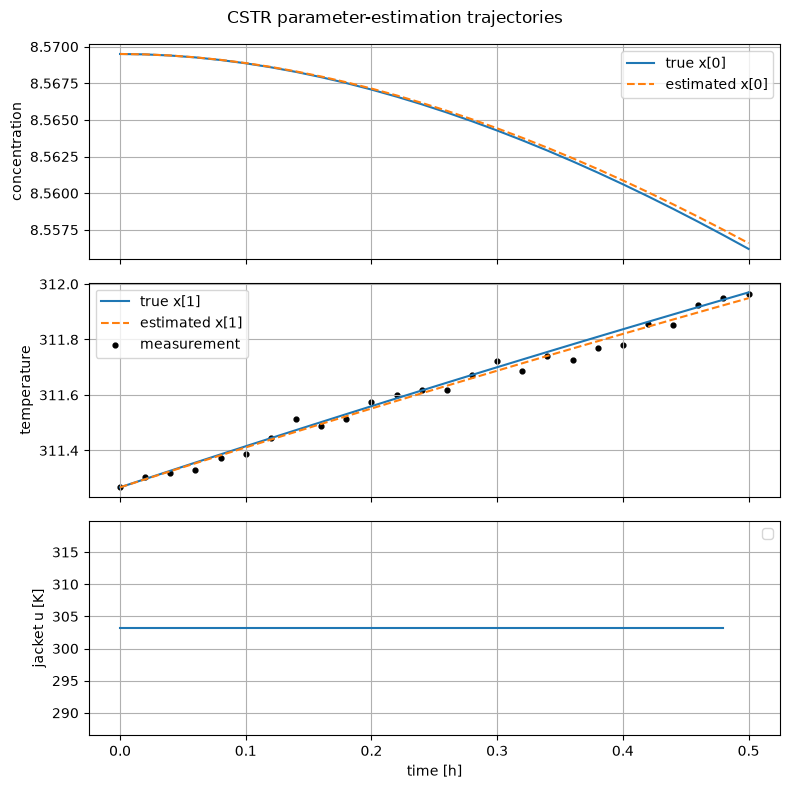

In [8]:
optimization = ca.Opti()
heat_transfer_estimate = optimization.variable()
x_estimate = optimization.variable(2, number_of_steps + 1)

optimization.subject_to(x_estimate[:, 0] == parameters.nominal_state)
optimization.subject_to(optimization.bounded(50, heat_transfer_estimate, 300))
estimated_parameters = replace(
    parameters,
    heat_transfer=heat_transfer_estimate,
)

for index in range(number_of_steps):
    u_and_disturbance = ca.vertcat(
        u_profile[index],
        parameters.nominal_disturbance,
    )
    x_next = rk4_step(
        lambda x_value, held_values: cstr_rhs(
            x_value,
            held_values[:1],
            held_values[1:],
            estimated_parameters,
        ),
        x_estimate[:, index],
        u_and_disturbance,
        step_size,
    )
    optimization.subject_to(x_estimate[:, index + 1] == x_next)

temperature_residual = (x_estimate[1, :] - ca.DM(measured_temperature).T) / 0.03
optimization.minimize(ca.sumsqr(temperature_residual))
optimization.set_initial(heat_transfer_estimate, 130)
optimization.set_initial(x_estimate, x_true.T)
optimization.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0},
)

solution = optimization.solve()
x_estimated = solution.value(x_estimate).T
print(
    "estimated heat transfer:",
    solution.value(heat_transfer_estimate),
    "true heat transfer:",
    parameters.heat_transfer,
)
assert abs(solution.value(heat_transfer_estimate) - parameters.heat_transfer) < 10

x_time = step_size * np.arange(number_of_steps + 1)
u_time = x_time[:-1]
figure, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 8))
axes[0].plot(x_time, x_true[:, 0], label="true x[0]")
axes[0].plot(x_time, x_estimated[:, 0], "--", label="estimated x[0]")
axes[0].set_ylabel("concentration")
axes[1].plot(x_time, x_true[:, 1], label="true x[1]")
axes[1].plot(x_time, x_estimated[:, 1], "--", label="estimated x[1]")
axes[1].scatter(
    x_time,
    measured_temperature,
    s=12,
    color="black",
    label="measurement",
)
axes[1].set_ylabel("temperature")
axes[2].step(u_time, u_profile, where="post")
axes[2].set(xlabel="time [h]", ylabel="jacket u [K]")
for axis in axes:
    axis.grid(True)
    axis.legend()
figure.suptitle("CSTR parameter-estimation trajectories")
figure.tight_layout()
plt.show()

Identifiability is not the same as solver convergence: an uninformative input may give a flat objective even when IPOPT reports success. Inspect parameter sensitivity, confidence under noise, and correlations.

**Common mistakes:** using inconsistent CSTR parameter cases, estimating parameters without bounds, and fitting process noise as physics. **Recap:** validate residuals and simulations before estimation. [Exercises](../exercises/05_cstr.ipynb).
